In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

from tqdm.notebook import tqdm

In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

In [3]:
encoder = nn.Sequential(
    nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 64) 
).to("cuda")

classifier_head = nn.Linear(64, 10).to("cuda")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(list(encoder.parameters()) + list(classifier_head.parameters()), lr=1e-3)

In [4]:
beta = torch.linspace(1e-4, 0.02, 500).to("cuda")
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

for epoch in tqdm(range(5), desc="Total Epochs"):
    encoder.train()
    classifier_head.train()
    pbar = tqdm(loader, desc=f"Epoch {epoch} Training", leave=False)
    
    for imgs, labels in pbar:
        imgs, labels = imgs.to("cuda"), labels.to("cuda")
        B = imgs.shape[0]

        t = torch.randint(0, 500, (B,), device="cuda").long()
        noise = torch.randn_like(imgs)
        
        a_bar = alpha_bar[t].view(-1, 1, 1, 1)
        
        noised_imgs = torch.sqrt(a_bar) * imgs + torch.sqrt(1 - a_bar) * noise
        
        features = encoder(noised_imgs)
        logits = classifier_head(features)
        loss = criterion(logits, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    encoder.eval()
    classifier_head.eval()
    correct, total = 0, 0
    
    with torch.no_grad():
        for imgs, labels in tqdm(test_loader, desc="Testing", leave=False):
            imgs, labels = imgs.to("cuda"), labels.to("cuda")


            B = imgs.shape[0]

            t = torch.randint(0, 500, (B,), device="cuda").long()
            noise = torch.randn_like(imgs)
            
            a_bar = alpha_bar[t].view(-1, 1, 1, 1)
            
            noised_imgs = torch.sqrt(a_bar) * imgs + torch.sqrt(1 - a_bar) * noise
            
            features = encoder(noised_imgs)
            logits = classifier_head(features)
            
            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch {epoch} | Clean Test Accuracy: {accuracy:.2f}%")

Total Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 0 Training:   0%|          | 0/469 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 0 | Clean Test Accuracy: 71.49%


Epoch 1 Training:   0%|          | 0/469 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

... (6 outputs left out)

Epoch 3 | Clean Test Accuracy: 72.46%


Epoch 4 Training:   0%|          | 0/469 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 4 | Clean Test Accuracy: 72.45%


In [5]:
all_numbers, all_labels = next(iter(DataLoader(train_set, batch_size=5000, shuffle=True)))
all_numbers, all_labels = all_numbers.cuda(), all_labels.cuda()
cond_numbers = train_set.data[train_set.targets == 8].cuda().unsqueeze(1) / 255
cond_numbers = (cond_numbers - 0.5) / 0.5

In [6]:
with torch.no_grad():
    phi_all = encoder(all_numbers)
    phi_eight = encoder(cond_numbers)


n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.1

H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(64).to("cuda")

h = torch.mean(phi_eight, dim=0, keepdim=True).T

theta = torch.linalg.solve(H, h)

In [7]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# biCls = BinaryClassifier().to(device)
# cls = Classifier().to(device)
model = uNet().to(device)

# biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
# cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

In [9]:
img_size = 28
batch_size = 128
epochs = 100
timesteps = 500
img_size = 28

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

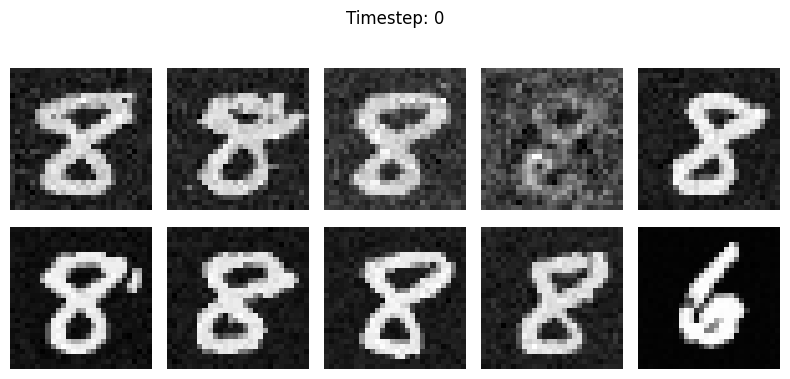

In [10]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# ... (Previous code: model, encoder, theta, alpha, beta setup) ...

n_samples = 50
s = 100.0  # Set scale > 0 to see the guidance effect
img_size = 28
device = "cuda"

# Start with random noise
xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    # 1. Unconditional prediction (no grad needed)
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    # Standard Diffusion Mean
    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)
    
    features = encoder(xt_for_grad)
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score
    
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    # 4. Live Plotting
    if i % 20 == 0 or i == 0:
        clear_output(wait=True)
    
        imgs = xt[:10].detach().cpu()
    
        fig, axes = plt.subplots(2, 5, figsize=(8, 4))
        axes = axes.flatten()
    
        for j in range(10):
            axes[j].imshow(imgs[j, 0].numpy(), cmap='gray')
            axes[j].axis('off')
    
        plt.suptitle(f"Timestep: {i}")
        plt.tight_layout()
        plt.show()